In [13]:
import yfinance as yf
import pandas as pd
import numpy as np
from scipy.optimize import minimize
import matplotlib.pyplot as plt

# Define the asset groups based on the 'treatonomics' context
# Affordable treats companies: Cosmetics, homewares, collectibles, entertainment (e.g., EL: Estée Lauder, TJX: TJX Companies, HAS: Hasbro, LYV: Live Nation)
affordable_treats_tickers = [
    'EL',   # Estée Lauder (cosmetics)
    'LRLCY', # L'Oréal ADR (cosmetics)
    'ULTA', # Ulta Beauty (cosmetics retail)
    'COTY', # Coty (cosmetics)
    'TJX',  # TJX Companies (homewares/apparel)
    'ROST', # Ross Stores (homewares/apparel)
    'BBWI', # Bath & Body Works (personal care/home)
    'TGT',  # Target (homewares/retail)
    'WMT',  # Walmart (homewares/retail)
    'DLTR', # Dollar Tree (affordable retail)
    'DG',   # Dollar General (affordable retail)
    'HAS',  # Hasbro (toys/collectibles)
    'MAT',  # Mattel (toys/collectibles)
    'FNKO', # Funko (collectibles)
    'LYV',  # Live Nation (entertainment)
    'DIS',  # Disney (entertainment/theme parks)
    'NFLX', # Netflix (entertainment/streaming)
    'AMC',  # AMC Entertainment (entertainment/cinemas)
    'SPOT', # Spotify (entertainment/streaming)
    'WMG',  # Warner Music Group (entertainment/music)
    'BILI', # Bilibili (entertainment/streaming)
    'PLNT', # Planet Fitness (wellness/experiences)
    'YETI'  # YETI Holdings (lifestyle/affordable luxury)
]

# Durable Goods Index: Autos, appliances, home improvement, big-ticket items (20+ stocks)
durable_goods_tickers = [
    'F',    # Ford (autos)
    'GM',   # General Motors (autos)
    'TSLA', # Tesla (autos)
    'TM',   # Toyota (autos)
    'HMC',  # Honda (autos)
    'STLA', # Stellantis (autos)
    'RIVN', # Rivian (autos)
    'LCID', # Lucid (autos)
    'WHR',  # Whirlpool (appliances)
    'GE',   # GE Appliances (appliances)
    'TT',   # Trane Technologies (HVAC/appliances)
    'LII',  # Lennox International (HVAC/appliances)
    'HD',   # Home Depot (home improvement)
    'LOW',  # Lowe's (home improvement)
    'MAS',  # Masco (home improvement/building)
    'BLDR', # Builders FirstSource (building materials)
    'FBIN', # Fortune Brands (home/building products)
    'JCI',  # Johnson Controls (building systems)
    'NVR',  # NVR (homebuilding)
    'DHI',  # D.R. Horton (homebuilding)
    'LEN',  # Lennar (homebuilding)
    'TOL'   # Toll Brothers (homebuilding)
]

# Download historical data from yfinance (adjust start/end dates as needed)
start_date = '2015-01-01'  # Backtest from 2015 to current (assuming current date is 2025-08-11)
end_date = '2025-08-11'
data_affordable = yf.download(affordable_treats_tickers, start=start_date, end=end_date)['Close']
data_durable = yf.download(durable_goods_tickers, start=start_date, end=end_date)['Close']



/tmp/ipython-input-4259601088.py:64: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data_affordable = yf.download(affordable_treats_tickers, start=start_date, end=end_date)['Close']
[*********************100%***********************]  23 of 23 completed
/tmp/ipython-input-4259601088.py:65: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data_durable = yf.download(durable_goods_tickers, start=start_date, end=end_date)['Close']
[*********************100%***********************]  22 of 22 completed


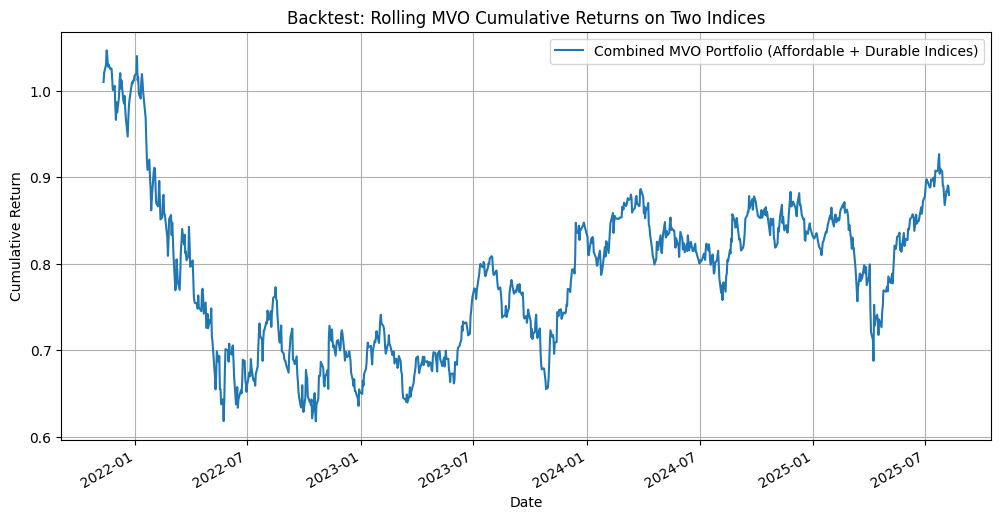

Combined Portfolio (MVO on Two Indices) Metrics:
Annualized Return: -0.19%
Annualized Volatility: 25.54%
Sharpe Ratio: -0.01

Weights History (Affordable_Index, Durable_Index):
Rebalance 1: 0.5000, 0.5000
Rebalance 2: 0.5000, 0.5000
Rebalance 3: 0.5000, 0.5000
Rebalance 4: 0.5000, 0.5000
Rebalance 5: 0.5000, 0.5000
Rebalance 6: 0.5000, 0.5000
Rebalance 7: 0.5000, 0.5000
Rebalance 8: 0.5000, 0.5000
Rebalance 9: 0.5000, 0.5000
Rebalance 10: 0.5000, 0.5000
Rebalance 11: 0.0000, 1.0000
Rebalance 12: 0.0000, 1.0000
Rebalance 13: 0.0000, 1.0000
Rebalance 14: 1.0000, 0.0000
Rebalance 15: 1.0000, 0.0000
Rebalance 16: 1.0000, 0.0000
Rebalance 17: 0.0000, 1.0000
Rebalance 18: 0.0000, 1.0000
Rebalance 19: 0.0000, 1.0000
Rebalance 20: 1.0000, 0.0000
Rebalance 21: 0.9529, 0.0471
Rebalance 22: 1.0000, 0.0000
Rebalance 23: 0.0000, 1.0000
Rebalance 24: 0.0000, 1.0000
Rebalance 25: 0.0000, 1.0000
Rebalance 26: 0.0000, 1.0000
Rebalance 27: 0.0000, 1.0000
Rebalance 28: 0.0000, 1.0000
Rebalance 29: 0.6975

In [14]:
# Compute daily returns
returns_affordable = data_affordable.pct_change().dropna()
returns_durable = data_durable.pct_change().dropna()

# Create equal-weight indices
affordable_index_returns = returns_affordable.mean(axis=1)
durable_index_returns = returns_durable.mean(axis=1)

# Combine into a single DataFrame for MVO (treating indices as two assets)
combined_returns = pd.DataFrame({
    'Affordable_Index': affordable_index_returns,
    'Durable_Index': durable_index_returns
})

# Function to perform Mean-Variance Optimization (MVO) for maximum Sharpe ratio
def mvo_optimize(returns, risk_free_rate=0.02):
    def portfolio_performance(weights, mean_returns, cov_matrix):
        port_return = np.dot(weights, mean_returns)
        port_vol = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))
        return port_return, port_vol

    def neg_sharpe(weights, mean_returns, cov_matrix, risk_free_rate):
        port_return, port_vol = portfolio_performance(weights, mean_returns, cov_matrix)
        return - (port_return - risk_free_rate) / port_vol  # Negative Sharpe for minimization

    mean_returns = returns.mean() * 252  # Annualize
    cov_matrix = returns.cov() * 252  # Annualize

    num_assets = len(mean_returns)
    args = (mean_returns, cov_matrix, risk_free_rate)
    constraints = ({'type': 'eq', 'fun': lambda x: np.sum(x) - 1})  # Weights sum to 1
    bounds = tuple((0, 1) for _ in range(num_assets))  # No shorting

    result = minimize(neg_sharpe, num_assets * [1. / num_assets], args=args,
                      method='SLSQP', bounds=bounds, constraints=constraints)
    return result.x

# Function to run rolling MVO backtest
def rolling_mvo_backtest(returns, window_size=252*3, rebalance_period=252, risk_free_rate=0.02):
    portfolio_returns = []
    dates = returns.index[window_size:]  # Start after first window
    weights_history = []

    for i in range(window_size, len(returns), rebalance_period):
        train_returns = returns.iloc[i - window_size:i]
        if i + rebalance_period > len(returns):
            test_returns = returns.iloc[i:]  # Last period may be shorter
        else:
            test_returns = returns.iloc[i:i + rebalance_period]

        weights = mvo_optimize(train_returns, risk_free_rate)
        weights_history.append(weights)
        port_ret = np.dot(test_returns, weights)
        portfolio_returns.extend(port_ret)

    portfolio_returns = pd.Series(portfolio_returns, index=dates[:len(portfolio_returns)])
    cumulative_returns = (1 + portfolio_returns).cumprod()
    return cumulative_returns, portfolio_returns, weights_history

# Parameters for backtest
window_size = 30 * 3  # 3-year rolling window (approx 756 trading days)
rebalance_period = 30  # Rebalance annually

# Run backtest for the combined portfolio (MVO on the two indices)
cum_combined, ret_combined, weights_history = rolling_mvo_backtest(combined_returns, window_size, rebalance_period)

# Plot cumulative returns
plt.figure(figsize=(12, 6))
cum_combined.plot(label='Combined MVO Portfolio (Affordable + Durable Indices)')
plt.title('Backtest: Rolling MVO Cumulative Returns on Two Indices')
plt.xlabel('Date')
plt.ylabel('Cumulative Return')
plt.legend()
plt.grid(True)
plt.show()

# Compute performance metrics
def compute_metrics(returns):
    ann_return = returns.mean() * 252
    ann_vol = returns.std() * np.sqrt(252)
    sharpe = ann_return / ann_vol
    return ann_return, ann_vol, sharpe

combined_metrics = compute_metrics(ret_combined)

print("Combined Portfolio (MVO on Two Indices) Metrics:")
print(f"Annualized Return: {combined_metrics[0]:.2%}")
print(f"Annualized Volatility: {combined_metrics[1]:.2%}")
print(f"Sharpe Ratio: {combined_metrics[2]:.2f}")

print("\nWeights History (Affordable_Index, Durable_Index):")
for i, w in enumerate(weights_history):
    print(f"Rebalance {i+1}: {w[0]:.4f}, {w[1]:.4f}")